# Feature Extraction and Price Prediction for Mobile Phones
Step-by-step version of `mobile_price_prediction.py`. Put the dataset at `data/Processed_Flipdata.xlsx` and run all cells.

In [1]:
# On Google Colab: upload mobile_price_prediction.py and the CSV (into a data/ folder) first
import pandas as pd
from IPython.display import Image, display, Markdown
import mobile_price_prediction as mpp
mpp.ensure_dirs()
DATA = 'data/Processed_Flipdata.xlsx'

## 1. Data exploration

In [2]:
raw = pd.read_excel(DATA)
raw_info = mpp.explore(raw)
raw.describe(include='all').T


=== 1. DATA EXPLORATION ===
Shape: (541, 12)
   Unnamed: 0            Model        Colour  Memory  RAM  Battery_  \
0           0  Infinix SMART 7   Night Black      64    4      6000   
1           1  Infinix SMART 7    Azure Blue      64    4      6000   
2           2     MOTOROLA G32  Mineral Gray     128    8      5000   
3           3         POCO C50    Royal Blue      32    2      5000   
4           4  Infinix HOT 30i      Marigold     128    8      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          16.64   
3         8MP          5MP        0          16.56   
4        50MP          5MP        1          16.76   

                   Processor_  Prize  
0  Unisoc Spreadtrum SC9863A1   7299  
1  Unisoc Spreadtrum SC9863A1   7299  
2     Qualcomm Snapdragon 680  11999  
3          Mediatek Helio A22   5649  
4      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,NaN,NaN,NaN,289.711645,182.359185,0.0,135.0,273.0,434.0,642.0
Model,541,187,realme C55,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Colour,541,275,Yellow,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,541.0,NaN,NaN,NaN,110.550832,60.600694,16.0,64.0,128.0,128.0,256.0
RAM,541.0,NaN,NaN,NaN,5.397412,1.984923,2.0,4.0,6.0,8.0,8.0
Battery_,541.0,NaN,NaN,NaN,4871.5878,780.148862,800.0,5000.0,5000.0,5000.0,7000.0
Rear Camera,541,14,50MP,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Front Camera,541,13,16MP,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI Lens,541.0,NaN,NaN,NaN,0.062847,0.242911,0.0,0.0,0.0,0.0,1.0
Mobile Height,541.0,NaN,NaN,NaN,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94


## 2. Data preprocessing

In [3]:
df = mpp.standardize_columns(raw)
clean, num_cols, prep_log = mpp.preprocess(df)
clean.head()


=== 2. DATA PREPROCESSING ===
 - Dropped 0 rows with missing/invalid price.
 - Removed 10 exact duplicate rows.
 - Removed 216 colour-variant rows (same model, specs and price, different colour). In 93% of spec groups every colour has the same price, so colour does not drive price; keeping one row per phone prevents the same phone appearing in both train and test sets (data leakage).
 - Replaced 1 out-of-range values in 'mobile_height' with median.
 - Capped 8 price outliers to the 1st-99th percentile range (Rs 1,310 - Rs 76,639).
Clean shape: (315, 15)


,model,colour,memory,ram,battery,rear_camera,front_camera,ai_lens,mobile_height,processor,price,brand,processor_family,processor_tier,colour_group
0,Infinix SMART 7,Night Black,64.0,4.0,6000.0,13.0,5.0,1.0,16.76,Unisoc Spreadtrum SC9863A1,7299.0,Infinix,Unisoc,Entry,Black
2,MOTOROLA G32,Mineral Gray,128.0,8.0,5000.0,50.0,16.0,0.0,16.64,Qualcomm Snapdragon 680,11999.0,Motorola,Qualcomm Snapdragon,Mid,Grey
3,POCO C50,Royal Blue,32.0,2.0,5000.0,8.0,5.0,0.0,16.56,Mediatek Helio A22,5649.0,Poco,MediaTek Helio,Entry,Blue
4,Infinix HOT 30i,Marigold,128.0,8.0,5000.0,50.0,5.0,1.0,16.76,G37,8999.0,Infinix,MediaTek Helio,Entry,Gold
8,Infinix HOT 30i,Diamond White,64.0,4.0,5000.0,50.0,5.0,1.0,16.76,G37,7999.0,Infinix,MediaTek Helio,Entry,White


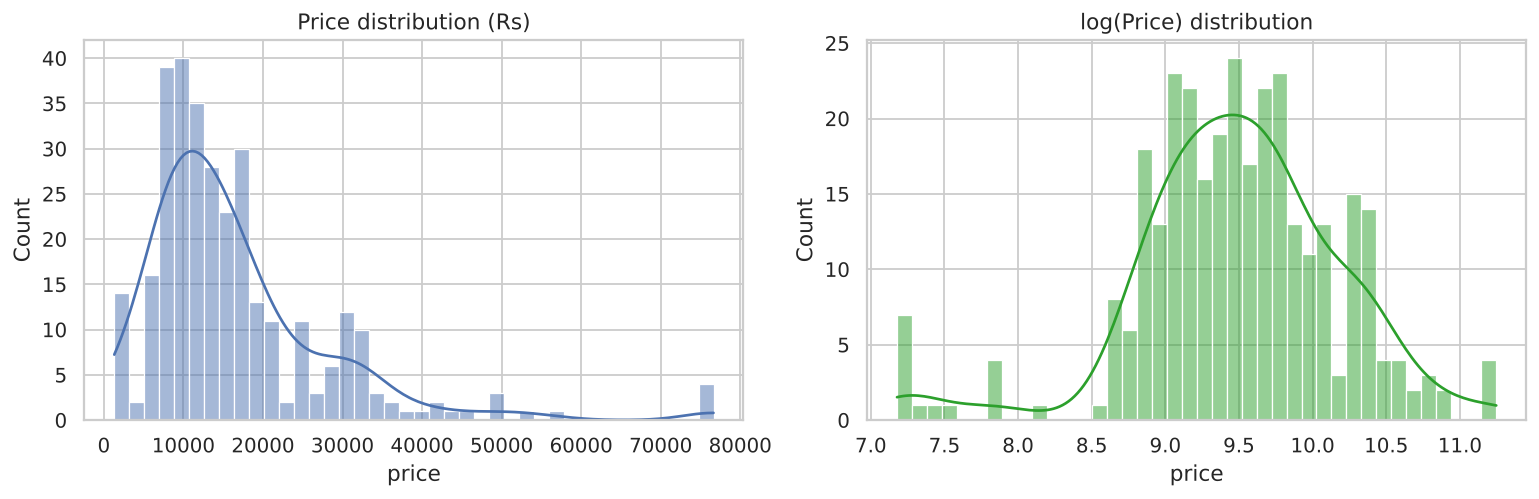

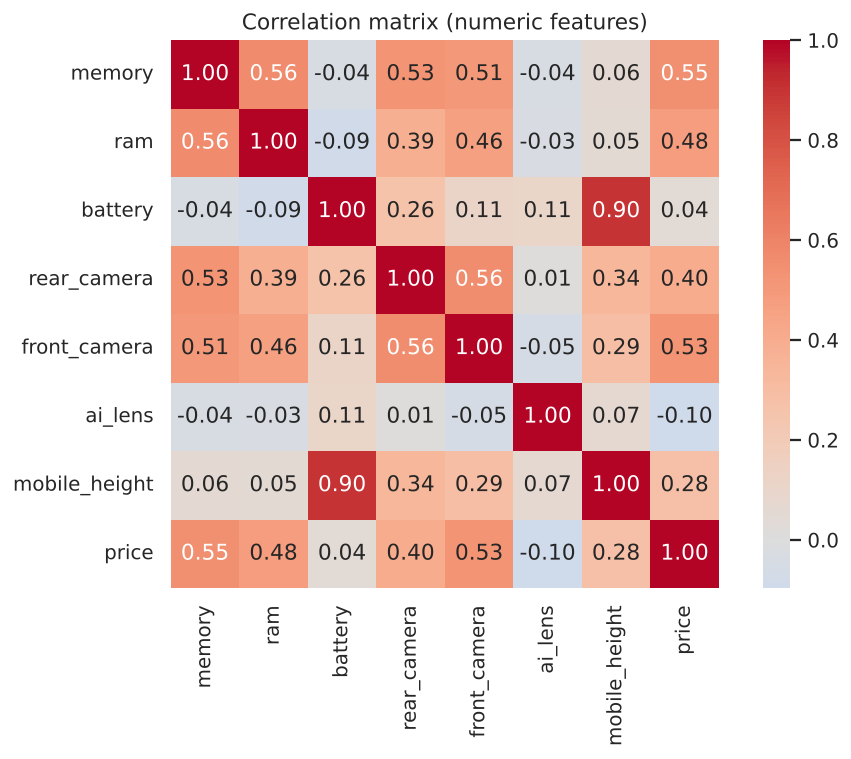

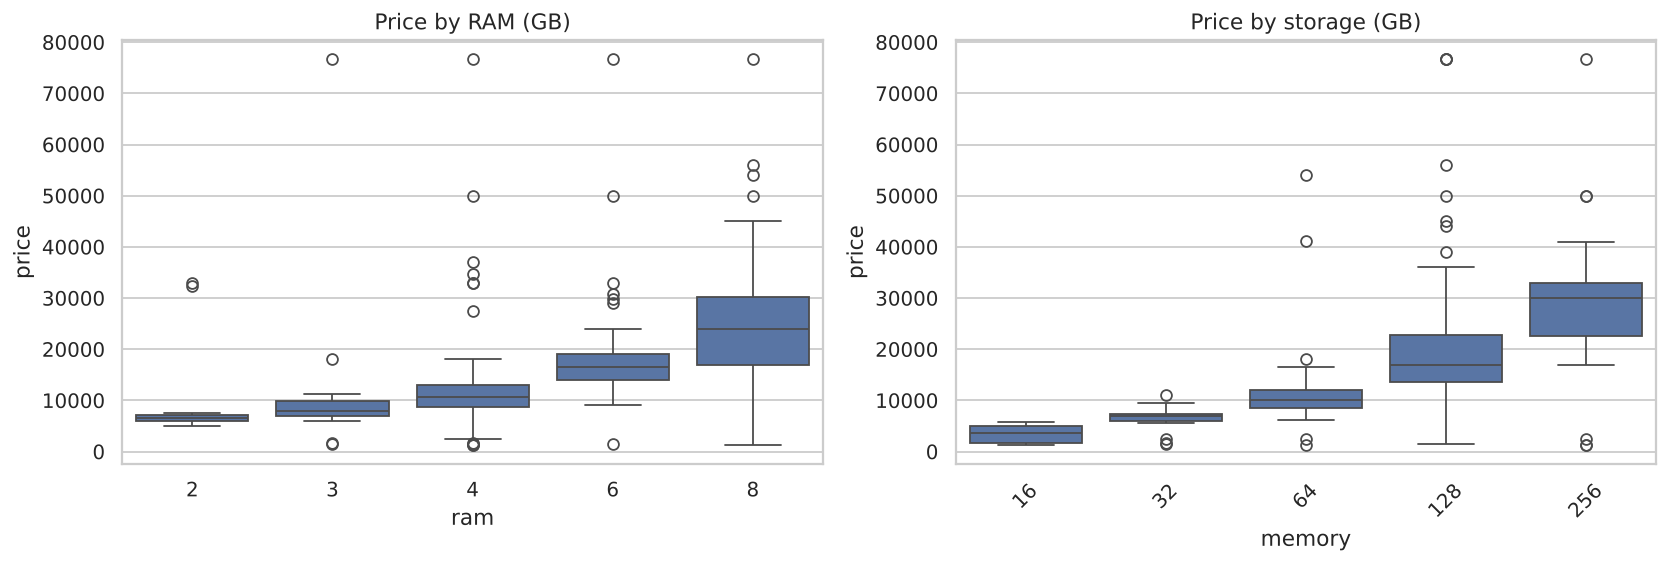

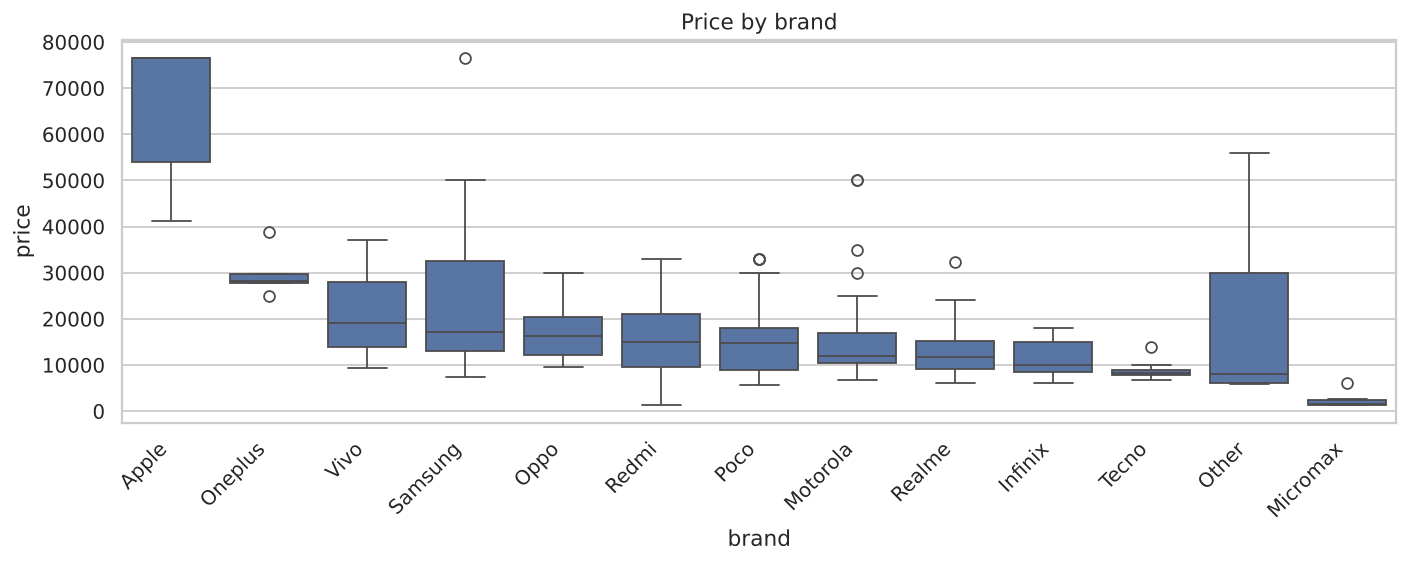

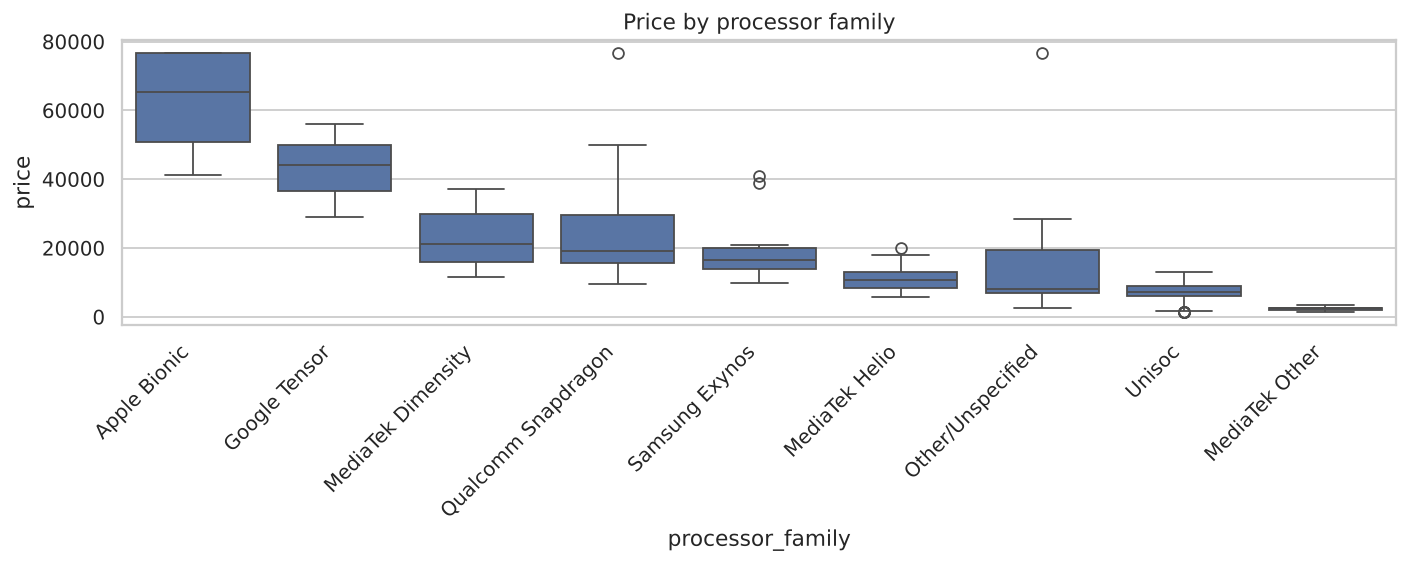

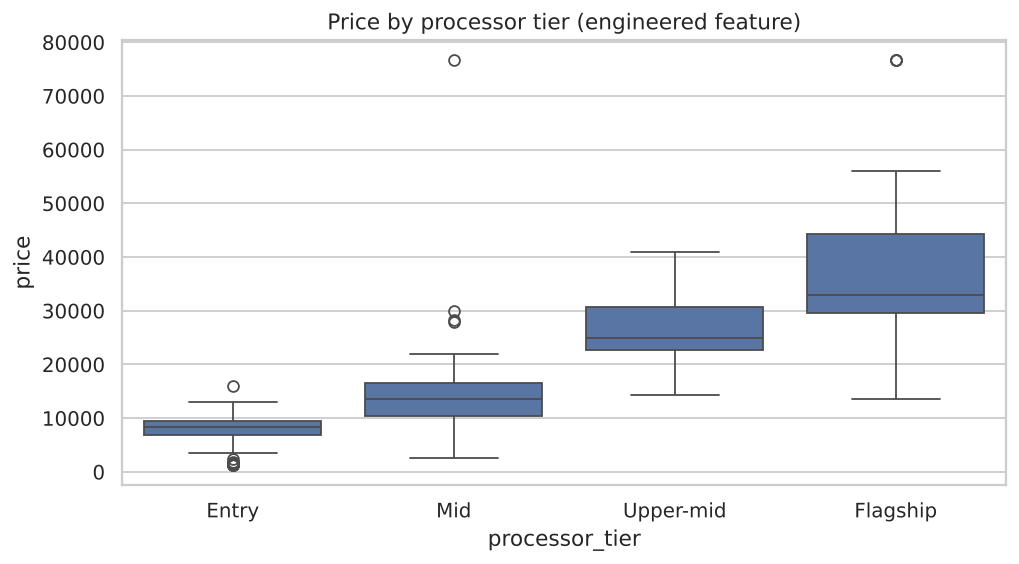

In [4]:
mpp.eda_plots(clean, num_cols)
for f in ['01_price_distribution','02_correlation_heatmap','03_price_by_ram_storage','04_price_by_brand','05_price_by_processor','05b_price_by_processor_tier']:
    display(Image(f'figures/{f}.png'))

## 3. Encoding & feature extraction

(315, 46)

=== 3. FEATURE EXTRACTION ===
               pearson_r  spearman_r
front_camera    0.532379    0.812946
memory          0.550251    0.745192
ram             0.483621    0.692579
rear_camera     0.404130    0.654364
mobile_height   0.277952    0.301081
ai_lens        -0.096774   -0.106431
battery         0.041598   -0.209733


SelectKBest (k=10): ['memory', 'ram', 'battery', 'rear_camera', 'front_camera', 'mobile_height', 'brand_Micromax', 'proc_Unisoc', 'tier_Entry', 'tier_Flagship']


PCA: 33 components explain 95% of variance; PC1 driven by ['rear_camera', 'front_camera', 'tier_Entry', 'memory', 'ram']


,pearson_r,spearman_r
front_camera,0.532379,0.812946
memory,0.550251,0.745192
ram,0.483621,0.692579
rear_camera,0.404130,0.654364
mobile_height,0.277952,0.301081
ai_lens,-0.096774,-0.106431
battery,0.041598,-0.209733


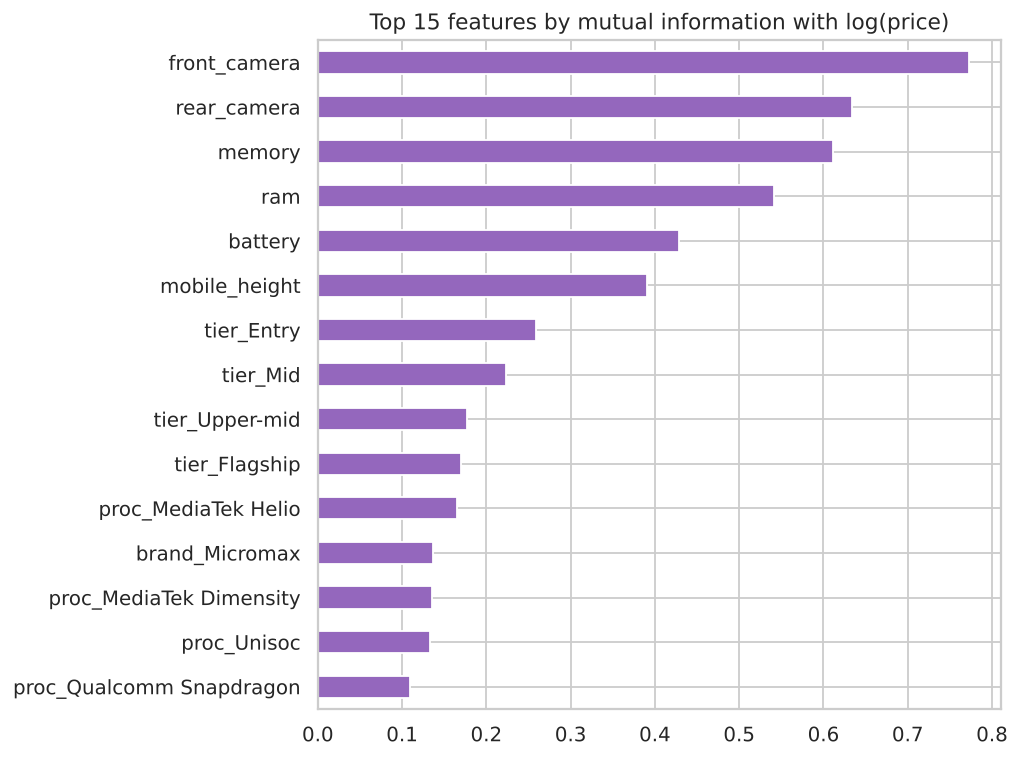

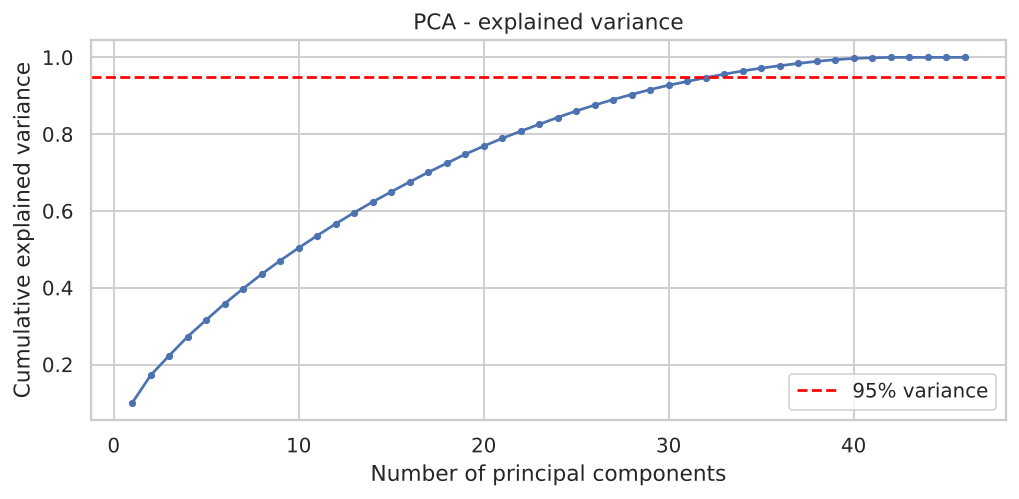

In [5]:
X, y = mpp.encode(clean, num_cols)
print(X.shape)
fe = mpp.feature_extraction(clean, num_cols, X, y)
display(fe['corr'])
for f in ['06_mutual_information','07_pca_variance']:
    display(Image(f'figures/{f}.png'))

## 4–5. Model building & evaluation


=== 4-5. MODEL BUILDING & EVALUATION ===
Linear Regression  MAE=3,019  RMSE=6,923  R2=0.711  MAPE=15.1%  CV-R2=0.912
Decision Tree      MAE=2,960  RMSE=4,737  R2=0.865  MAPE=17.0%  CV-R2=0.871


Random Forest      MAE=2,479  RMSE=5,026  R2=0.848  MAPE=12.1%  CV-R2=0.921


Gradient Boosting  MAE=1,730  RMSE=3,239  R2=0.937  MAPE=9.4%  CV-R2=0.946
Best model: Gradient Boosting


,Model,MAE,RMSE,R2,MAPE_%,CV_R2_log
0,Gradient Boosting,1729.989335,3239.354926,0.936762,9.389948,0.945926
1,Decision Tree,2959.685267,4736.822743,0.864782,16.992081,0.871357
2,Random Forest,2478.680956,5026.355738,0.847747,12.142234,0.921041
3,Linear Regression,3019.477577,6922.889960,0.711175,15.072607,0.911534


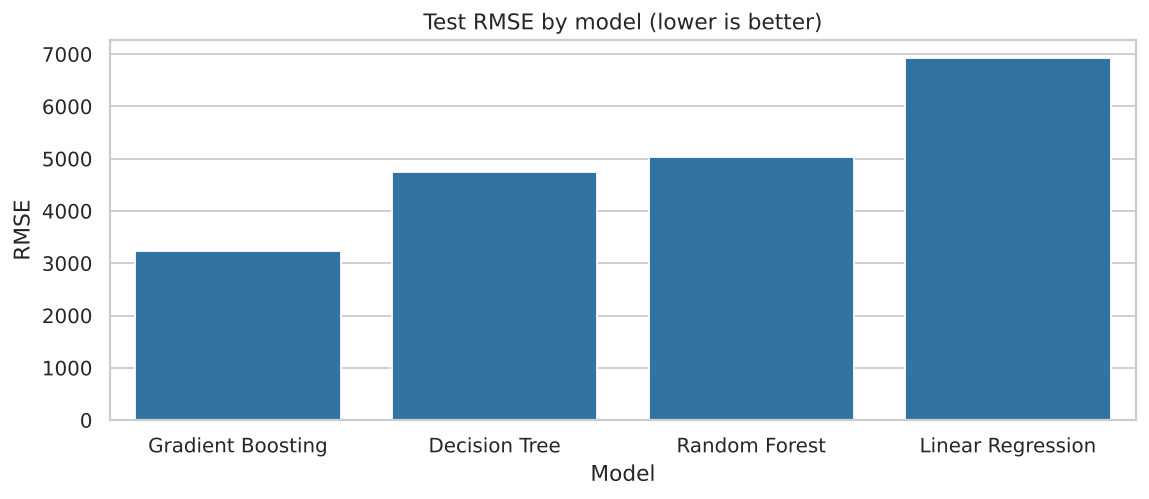

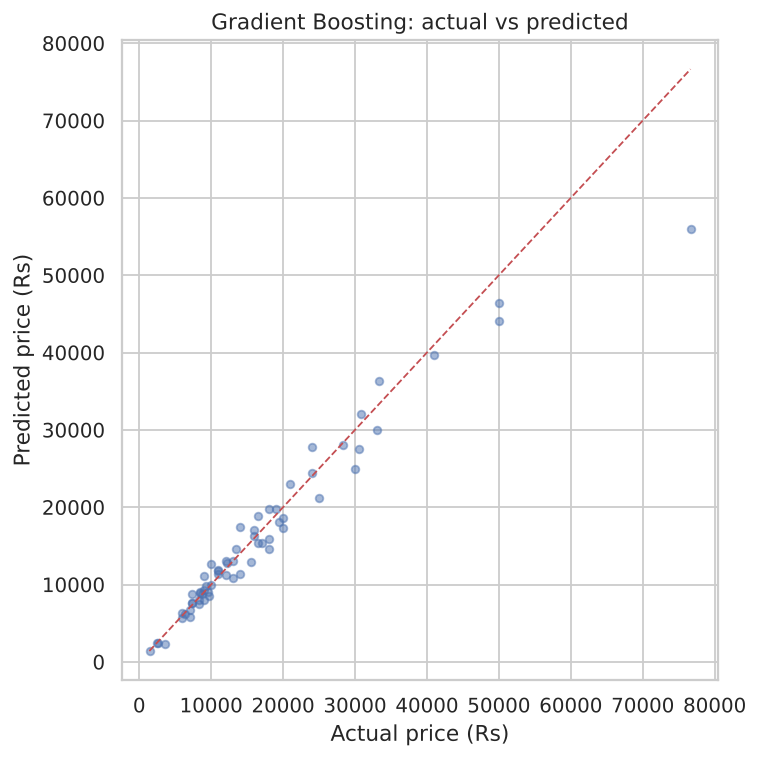

In [6]:
results, best, fitted, splits = mpp.build_and_evaluate(X, y)
display(results)
for f in ['08_model_comparison','09_actual_vs_predicted']:
    display(Image(f'figures/{f}.png'))

## 6. Feature importance analysis


=== 6. FEATURE IMPORTANCE ===


                  impurity  permutation  impurity_%
front_camera        0.4365       0.3147     43.6452
rear_camera         0.1359       0.0852     13.5925
processor_tier      0.0611       0.0409      6.1063
battery             0.1402       0.0381     14.0228
memory              0.0653       0.0324      6.5349
brand               0.0359       0.0270      3.5915
mobile_height       0.0723       0.0188      7.2274
ram                 0.0223       0.0186      2.2274
processor_family    0.0203       0.0133      2.0265
colour              0.0102       0.0031      1.0197
ai_lens             0.0001       0.0003      0.0056


,impurity,permutation,impurity_%
front_camera,0.436452,0.314658,43.645197
rear_camera,0.135925,0.085240,13.592535
processor_tier,0.061063,0.040937,6.106338
battery,0.140228,0.038084,14.022806
memory,0.065349,0.032411,6.534922
brand,0.035915,0.026961,3.591503
mobile_height,0.072274,0.018803,7.227394
ram,0.022274,0.018618,2.227449
processor_family,0.020265,0.013258,2.026536
colour,0.010197,0.003112,1.019695


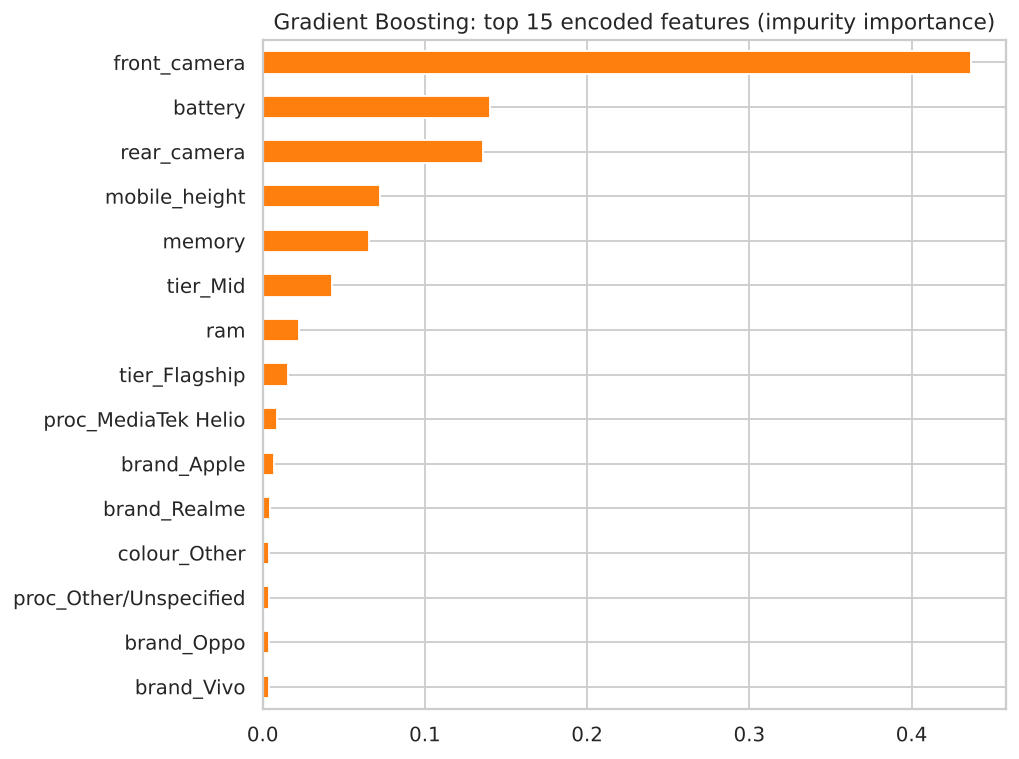

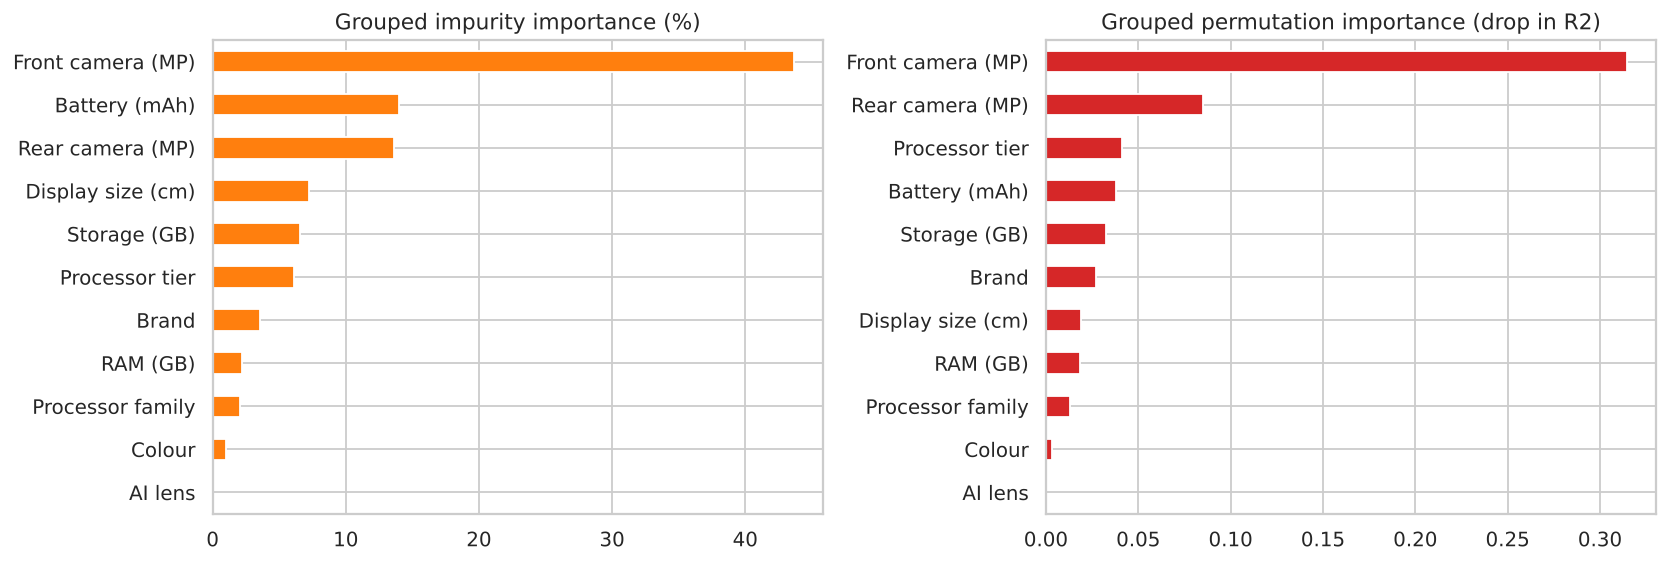

In [7]:
grouped, tree_name = mpp.feature_importance(fitted, best, splits)
display(grouped)
for f in ['10_feature_importance_detailed','11_feature_importance_grouped']:
    display(Image(f'figures/{f}.png'))

## 7. Report, key insights & recommendations

In [8]:
mpp.write_report(raw_info, clean, prep_log, fe, results, best, grouped, tree_name)
report = open('reports/REPORT.md', encoding='utf-8').read()
display(Markdown(report[report.index('## 7. Key insights'):report.index('## 9.')]))


Report written to reports/REPORT.md


## 7. Key insights
**Front camera** – the single strongest signal; it tracks the phone's overall segment:

| front camera | phones | median price (Rs) |
|---|---|---|
| None | 15 | 1,599 |
| 2-8 MP | 146 | 9,443 |
| 10-16 MP | 126 | 17,999 |
| 20 MP+ | 28 | 29,708 |

**RAM:** 2 GB → Rs 6,549, 3 GB → Rs 7,999, 4 GB → Rs 10,699, 6 GB → Rs 16,499, 8 GB → Rs 23,999 (median price).

**Storage:** 16 GB → Rs 3,549, 32 GB → Rs 6,988, 64 GB → Rs 9,999, 128 GB → Rs 16,999, 256 GB → Rs 29,999 (median price).

**Battery – non-linear:** budget phones ship the biggest batteries, flagships use slimmer 4,000–4,900 mAh cells, and feature phones have tiny ones:

| battery (mAh) | phones | median price (Rs) |
|---|---|---|
| < 3000 | 16 | 1,649 |
| 3000-4999 | 58 | 29,644 |
| 5000 | 215 | 12,499 |
| > 5000 | 26 | 11,249 |

**Brand:** highest median prices – Apple (Rs 76,639), Oneplus (Rs 28,298), Vivo (Rs 18,999), Samsung (Rs 17,249).

**AI lens:** phones with one have a *lower* median price (Rs 9,999 vs Rs 13,499) – it is a budget-phone marketing feature, not a premium one.

## 8. Recommendations for the organisation
1. **Build the price ladder on processor tier, cameras and memory.** These explain most of the price variation. Use processor tier to set the segment, then camera and RAM/storage configuration to position a phone within it.
2. **Use RAM/storage variants as the main upsell.** Moving from 4 GB to 8 GB RAM is associated with a median price jump of Rs 10,699 → Rs 23,999, and 64 GB → 128 GB storage with Rs 9,999 → Rs 16,999. Stock 2–3 memory variants per model and display RAM/storage prominently on listings.
3. **Highlight camera specs in marketing.** Front and rear camera megapixels are the most visible quality signal customers pay for; feature them first in product titles and ads.
4. **Market the chipset's tier, not its brand.** Customers pay for performance level – a flagship-class chip commands a premium regardless of whether it is Snapdragon or Dimensity. Use terms like "flagship processor" or "5G gaming chip".
5. **Don't charge extra for colour or AI-lens claims.** Colour variants sell at the same price, and AI-lens phones are budget models. Use colours to widen choice and drive conversion, not as a price lever.
6. **Promote large batteries in the budget segment.** 6,000 mAh+ is a selling point for value buyers, not a premium feature.
7. **Adopt the model as a pricing tool.** With ~Rs 1,730 average error it can flag listings priced well above or below what their specs justify and suggest launch prices for new SKUs. Retrain it every quarter as the market moves.

